# 03 · Model: Logistic Regression on Status Only (Baseline)

The baseline answers: **how well does a one-time snapshot predict newly needing help a year later?** It uses only
each person's status *now* (round `t`): difficulty, device use, doing less and going without for the 7 activities,
falls, pain, mood, memory, self-rated health, age, sex, living alone and proxy interview. No change since last year.
Race/ethnicity and income are never inputs.

Rules from the proposal (04 Avoiding overfitting), implemented in `src/willow/models.py` and `metrics.py`:
- **Split:** 30% of people held out, *and* train on earlier years / test on later years.
- **Tuning:** 5-fold cross-validation on training data, grouped by person.
- **Calibration:** Platt scaling on the training out-of-fold predictions. No oversampling.
- **Test set used once,** with 95% CIs from a bootstrap that resamples people.

Show aggregate results only. Clear outputs before committing.

In [1]:
import sys
from pathlib import Path

for root in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (root / "src" / "willow").exists():
        sys.path.insert(0, str(root / "src"))
        break
for name in list(sys.modules):
    if name == "willow" or name.startswith("willow."):
        del sys.modules[name]

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from willow import models as md, metrics as mt
from willow.data import ROOT, load_panel
from willow.features import analytic_windows, build_windows, make_X
from willow.schema import ITEM_LABELS

pd.set_option("display.max_columns", 40, "display.width", 160, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
YEAR = {r: 2010 + r for r in range(1, 30)}

OUTCOME = "y_any"        # newly receives help with any of the 7 activities at t+1
FEATURES = "status"      # status now only (baseline)
SPLIT_ROUND = 11         # train: outcomes up to 2021; test: windows from 2021 on (outcomes 2022-2024)
NAME = "lr_status"

## 1. Analytic Sample And Split

Only windows with an observed outcome are used (the person was still at home and interviewed at `t+1`). Training
people contribute windows whose outcome is in or before the split year; held-out people contribute windows from the
split year on. Windows outside those two sets are not used, so no person and no year is in both.

In [2]:
a = analytic_windows(build_windows(load_panel()), OUTCOME)
train, test = md.person_time_split(a, SPLIT_ROUND)

def describe(d):
    return {"windows": len(d), "people": d.person_id.nunique(), "events": int(d[OUTCOME].sum()),
            "new help (%)": 100 * d[OUTCOME].mean(),
            "years (t -> t+1)": f"{YEAR[d['round'].min()]}->{YEAR[d['round'].min() + 1]} ... {YEAR[d['round'].max()]}->{YEAR[d['round'].max() + 1]}"}

assert set(train.person_id).isdisjoint(test.person_id)
pd.DataFrame({"all observed": describe(a), "train": describe(train), "test": describe(test)}).T

[data] cached panel data/clean/panel.parquet (refresh=True to rebuild)


,windows,people,events,new help (%),years (t -> t+1)
all observed,35632,7992,3289,9.23,2012->2013 ... 2023->2024
train,19553,4333,1820,9.308,2012->2013 ... 2020->2021
test,2300,1234,215,9.348,2021->2022 ... 2023->2024


## 2. Features

Missing values are filled with the training median inside the model, and a missing-value flag is added for each
input that has gaps, so "not answered" can carry its own signal.

In [3]:
X_train, y_train = make_X(train, FEATURES), train[OUTCOME].values
X_test, y_test = make_X(test, FEATURES), test[OUTCOME].values
print(f"{X_train.shape[1]} features")
pd.DataFrame({"label": [ITEM_LABELS.get(c.removeprefix("cur_"), c) for c in X_train.columns],
              "% missing (train)": 100 * X_train.isna().mean().values}, index=X_train.columns)

37 features


,label,% missing (train)
cur_go_outside_diff,Difficulty go outside alone,0.450
cur_get_around_inside_diff,Difficulty get around inside alone,0.036
cur_get_out_of_bed_diff,Difficulty get out of bed alone,0.010
cur_eating_diff,Difficulty eating alone,0.031
cur_bathing_diff,Difficulty bathing alone,0.020
cur_toileting_diff,Difficulty toileting alone,0.015
cur_dressing_diff,Difficulty dressing alone,0.153
cur_go_out_freq,"How often goes outside (0 = every day, 4 = never)",0.010
cur_self_rated_health,Self-rated health (1 excellent - 5 poor),0.036
cur_phq2,"Depressive symptoms (PHQ-2, 0-6)",0.547


## 3. Tune On Training Data

The only setting to choose is the penalty strength `C` (smaller = stronger shrinkage of the coefficients). Each value
is scored by 5-fold cross-validation with every person kept inside one fold.

In [4]:
folds = md.grouped_folds(train, OUTCOME)
cv_table, best_C, oof = md.tune_logistic(X_train, y_train, folds)
print(f"chosen C = {best_C} (highest cross-validated AUROC)")
cv_table

chosen C = 0.001 (highest cross-validated AUROC)


,C,cv_auroc,cv_log_loss
0,1.000e-04,0.776,0.283
1,3.000e-04,0.778,0.274
2,1.000e-03,0.778,0.269
3,3.000e-03,0.776,0.268
4,1.000e-02,0.774,0.268
5,1.000e-01,0.773,0.269
6,1.000e+00,0.772,0.271


## 4. Fit, Recalibrate, Test Once

The final model is fit on all training data. Platt scaling, learned from the out-of-fold training predictions, turns
its scores into calibrated risks. The alert threshold flags the top 20% of *training* risks and is then applied
unchanged to the test set. Proposal targets: AUROC ≥ 0.75 and observed/expected between 0.9 and 1.1.

In [5]:
model = md.logistic(best_C).fit(X_train, y_train)
platt = md.platt_fit(oof, y_train)
p_train = md.platt_apply(platt, oof)
threshold = mt.alert_threshold(p_train)
p_test = md.platt_apply(platt, model.predict_proba(X_test)[:, 1])

results = mt.bootstrap_ci(y_test, p_test, test.person_id.values, threshold)
display(results)
mt.check_targets(results["estimate"].to_dict())

,estimate,ci_low,ci_high
auroc,0.745,0.712,0.781
auprc,0.257,0.209,0.312
brier,0.079,0.071,0.088
obs_exp,0.904,0.797,1.020
cal_slope,0.881,0.755,1.022
cal_intercept,-0.351,-0.656,-0.048
flagged_pct,23.565,21.280,25.920
sensitivity,0.558,0.486,0.618
precision,0.221,0.186,0.256
prevalence,0.093,0.082,0.106


,metric,value,target,met
0,auroc,0.745,≥ 0.75,no
1,obs_exp,0.904,0.9–1.1,yes


## 5. Calibration

Each point is one tenth of the test set, grouped by predicted risk. Points on the diagonal mean predicted risk matches
what actually happened.

,bin,n,predicted,observed
0,0,233,0.029,0.017
1,1,227,0.037,0.031
2,2,230,0.044,0.030
3,3,230,0.051,0.043
4,4,230,0.059,0.043
5,5,230,0.071,0.087
6,6,230,0.087,0.100
7,7,230,0.114,0.126
8,8,230,0.173,0.187
9,9,230,0.370,0.270


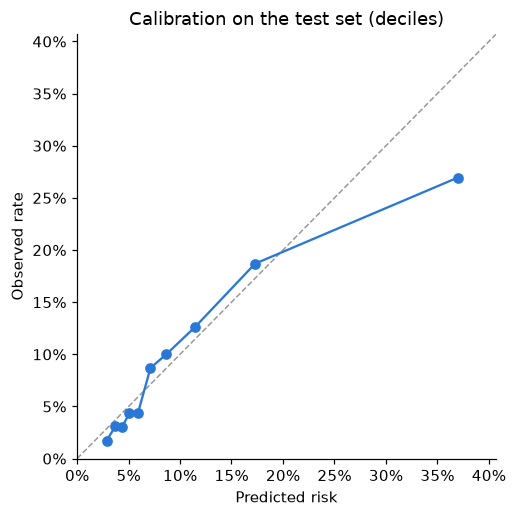

In [6]:
cal = mt.calibration_table(y_test, p_test)
lim = max(cal.predicted.max(), cal.observed.max()) * 1.1
fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.plot([0, lim], [0, lim], ls="--", color="#999", lw=1)
ax.plot(cal.predicted, cal.observed, "o-", color="#2a78d6", ms=6)
ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="Predicted risk", ylabel="Observed rate",
       title="Calibration on the test set (deciles)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()
cal

## 6. What Drives The Baseline

Odds ratios per one standard deviation of each input (inputs are standardised, so effects are comparable). Above 1
raises risk, below 1 lowers it. Strong shrinkage makes all effects small; their order is what matters.

In [7]:
coefs = md.coefficients(model, list(X_train.columns))
coefs.insert(1, "label", [ITEM_LABELS.get(f.removeprefix("cur_").removesuffix(" (missing)"), f)
                          + (" (missing)" if f.endswith("(missing)") else "") for f in coefs.feature])
coefs.head(15)

,feature,label,coef,odds_ratio_per_sd
0,age,Age (5-year group),0.169,1.184
1,cur_dementia_class,"Dementia classification (0 none, 1 possible, 2...",0.165,1.180
2,lives_alone,Lives alone,-0.135,0.873
3,cur_go_out_freq,"How often goes outside (0 = every day, 4 = never)",0.134,1.144
4,cur_go_outside_device,Uses a device for go outside,0.125,1.133
5,cur_self_rated_health,Self-rated health (1 excellent - 5 poor),0.114,1.120
6,cur_get_around_inside_device,Uses a device for get around inside,0.100,1.105
7,cur_toileting_device,Uses a device for toileting,0.097,1.102
8,cur_dressing_diff,Difficulty dressing alone,0.093,1.097
9,cur_bathing_device,Uses a device for bathing,0.086,1.090


## 7. Save Aggregate Outputs

Everything saved is aggregate: metrics, the tuning table, the calibration table and the coefficients.

In [8]:
out = os.path.join(ROOT, "results")
results.assign(model=NAME, C=best_C, threshold=threshold).to_csv(os.path.join(out, f"model_{NAME}_metrics.csv"))
cv_table.to_csv(os.path.join(out, f"model_{NAME}_cv.csv"), index=False)
cal.to_csv(os.path.join(out, f"model_{NAME}_calibration.csv"), index=False)
coefs.to_csv(os.path.join(out, f"model_{NAME}_coefficients.csv"), index=False)
fig.savefig(os.path.join(out, f"fig_{NAME}_calibration.png"), dpi=200, bbox_inches="tight")
print(f"saved results/model_{NAME}_*.csv and results/fig_{NAME}_calibration.png")

saved results/model_lr_status_*.csv and results/fig_lr_status_calibration.png


## Takeaways

- **Baseline result (test set, outcomes 2022–2024):** AUROC 0.745 (95% CI 0.71–0.78), just under the 0.75 target.
  AUPRC 0.26 against a 9.3% base rate. Observed/expected 0.90, at the edge of the 0.9–1.1 target.
- **Flagging the top 20%** of risk catches about 56% of people who go on to need help, and about 1 in 5 flagged people
  does need help.
- **Calibration is good up to ~20% risk;** the highest-risk tenth is over-predicted (37% predicted vs 27% observed).
- **Strongest snapshot signals:** older age, dementia, going out less, using devices to go outside or move inside,
  poor self-rated health. **Living alone lowers predicted risk**, likely because the outcome is *receiving* help, and
  people living alone have fewer people around to give it (see the limitations).
- **Strong shrinkage** (C = 0.001) gave the best cross-validated AUROC: many status items overlap, so a few broad
  signals do most of the work.
- This is the bar the change-based models must beat. Compare them on the **same split** (`SPLIT_ROUND`, same seed),
  and read differences against the CIs: the test set has 215 events, so gaps of ~0.02 AUROC are within noise.